# <center><b>Model training, selection, and insight collection</b></center>

In [1]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error, r2_score
from sklearn.inspection import PartialDependenceDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib

C:\Users\Milky\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv('../CSVs/08_model_ready_dataset.csv').drop(columns=['Unnamed: 0'])

In [3]:
# Changing columns names for more readability
df.columns = [
    'village_code', 'visit_month', 'spray_status',
    'total_residents',
    'clinic_tests', 'total_rdts',
    'avg_distance_to_health_facility_km', 'incidence_per_1000',
    'positivity_rate', 'dist_missing', 'rainfall', 'rainfall_total',
    'humidity', 'temp', 'max_temp', 'min_temp', 'temp_range',
    'prev_rainfall', 'prev2_rainfall', 'prev3_rainfall', 'prev4_rainfall',
    'prev_rainfall_total', 'prev2_rainfall_total', 'prev3_rainfall_total',
    'prev4_rainfall_total', 'prev_humidity', 'prev2_humidity',
    'prev3_humidity', 'prev4_humidity', 'prev_temp', 'prev2_temp',
    'prev3_temp', 'prev4_temp', 'prev_max_temp', 'prev2_max_temp',
    'prev3_max_temp', 'prev4_max_temp', 'prev_min_temp', 'prev2_min_temp',
    'prev3_min_temp', 'prev4_min_temp', 'prev_temp_range',
    'prev2_temp_range', 'prev3_temp_range', 'prev4_temp_range',
    'prev_incidence_per_1000', 'prev_u5_incidence_per_1000', 'mpi'
]

# Performing manual train-test split

In [4]:
village_codes = df['village_code'].unique()
split_point_village = int(len(village_codes) * .8)
village_bool = df['village_code'] <= village_codes[split_point_village]
len(df[village_bool]), len(df[~village_bool])

(3002, 674)

In [5]:
dates = sorted(df['visit_month'].unique())
split_point_date = int(len(dates) * 0.7)

month_bool = df['visit_month'].isin(dates[:split_point_date])

len(df[month_bool]), len(df[~month_bool])

(2463, 1213)

In [6]:
df[month_bool]['visit_month'].unique(), df[~month_bool]['visit_month'].unique()

(<StringArray>
 ['2017-01-01', '2017-02-01', '2017-03-01', '2017-04-01', '2017-05-01',
  '2017-06-01', '2017-07-01', '2017-08-01', '2017-09-01', '2017-10-01',
  '2017-11-01', '2017-12-01', '2018-01-01', '2018-02-01', '2018-03-01']
 Length: 15, dtype: str,
 <StringArray>
 ['2018-04-01', '2018-05-01', '2018-06-01', '2018-07-01', '2018-08-01',
  '2018-09-01', '2018-10-01']
 Length: 7, dtype: str)

In [7]:
split_point_date

15

In [8]:
def chrono(chrono_bool):
    """
    Function for specifying which boolean to use for the (chronological or spatial) split
    """
    return month_bool if chrono_bool else village_bool

In [9]:
# The model seems to do a worse job when performing a chronological split instead of a spatial split
# This is possibly because the train data has noisy data and the model is forced to erraneously fit to and apply patterns on novel data.

In [10]:
# 80% / 20% chronological split
target_columns = ['incidence_per_1000'] # These are the columns our model tries to predict
# And these are poor or useless columns that carry information about which villages have suffered epidemics before
# Causing it to overfit by predicting historical average
useless_columns = ['prev_u5_incidence_per_1000', 'total_residents', 'visit_month', 'village_code', 'avg_distance_to_health_facility_km', 'clinic_tests',
                   'rainfall', 'rainfall_total', 'total_rdts', 'positivity_rate'] \
                + ['prev_rainfall', 'prev_rainfall_total', 'prev_min_temp', 'prev_max_temp', 'prev_temp', 'prev_humidity'] \
                + ['prev2_rainfall_total', 'prev3_rainfall_total', 'prev4_rainfall_total', 'prev_temp_range', 'prev2_temp_range',\
                   'prev3_temp_range', 'prev4_temp_range', 'temp_range', 'mpi'] # let's drop the MPI for now.
                 # + ['humidity', 'temp', 'max_temp', 'min_temp', 'temp_range', 'total_rdts']
# Train data becomes the majority (80%)
X_train = df[chrono(1)]
y_train = X_train[target_columns]
# Test data becomes the minority (20%)
X_test = df[~chrono(1)]
y_test = X_test[target_columns]
# We finally drop the target columns from the X data
X_train = X_train.drop(columns=target_columns + useless_columns) # We also don't need 'visit_month' anymore it isn't important in training
X_test = X_test.drop(columns=target_columns + useless_columns)

In [11]:
# Rolling-origin validation: train on months before m, validate on month m (last 4 training months)
train_months = df[chrono(1)]['visit_month'].values
months_sorted = sorted(set(train_months))
cv_splits = [(np.where(train_months < m)[0], np.where(train_months == m)[0])
             for m in months_sorted[-4:]]
print([str(m)[:7] for m in months_sorted[-4:]])

['2017-12', '2018-01', '2018-02', '2018-03']


In [12]:
len(X_test)

1213

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
linear = LinearRegression().fit(X_train_scaled, y_train)

model = RandomForestRegressor(max_depth=10, random_state=42).fit(X_train_scaled, np.ravel(y_train))

dt = DecisionTreeRegressor().fit(X_train_scaled, y_train)

knn = KNeighborsRegressor().fit(X_train_scaled, y_train)

In [15]:
ridge = GridSearchCV(
    Ridge(max_iter=2000),
    param_grid={ 'alpha': np.linspace(100, 1000, 10)},
    cv=cv_splits,
    n_jobs=2
)
ridge.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge(max_iter=2000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': array([ 100.,... 1000.])}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...shape=(1775,)), ...), (array([ 0, ...shape=(1942,)), ...), ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, def

In [16]:
lasso = GridSearchCV(
    Lasso(max_iter=2000),
    param_grid={ 'alpha': [.1, .2, .3, .4, .5] },
    cv=cv_splits,
    n_jobs=2,
)
lasso.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Lasso(max_iter=2000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.1, 0.2, ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...shape=(1775,)), ...), (array([ 0, ...shape=(1942,)), ...), ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Con

In [17]:
elasticnet = GridSearchCV(
    ElasticNet(max_iter=2000),
    param_grid={ 'alpha': [.001, .01, .1, 1, 100, 1000], 'l1_ratio': [.1, .3, .5, .7, .9] },
    cv=cv_splits,
    n_jobs=2,
)
elasticnet.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",ElasticNet(max_iter=2000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.001, 0.01, ...], 'l1_ratio': [0.1, 0.3, ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...shape=(1775,)), ...), (array([ 0, ...shape=(1942,)), ...), ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True

In [18]:
bv1_pred = []
for x in range(1, len(df['incidence_per_1000']) + 1):
    bv1_pred.append(df['incidence_per_1000'].mean())
bv1_pred = np.array(bv1_pred)

In [19]:
metrics_bv1 = [100 * r2_score(bv1_pred, df['incidence_per_1000']),\
               mean_absolute_error(bv1_pred, df['incidence_per_1000']), \
               root_mean_squared_error(bv1_pred, df['incidence_per_1000'])]
metrics_bv1

[0.0, 29.41413813237759, 46.38080048892255]

In [20]:
metrics_bv2 = knn_metrics = [100 * r2_score(df['prev_incidence_per_1000'], df['incidence_per_1000']),\
                             mean_absolute_error(df['prev_incidence_per_1000'], df['incidence_per_1000']), \
                             root_mean_squared_error(df['prev_incidence_per_1000'], df['incidence_per_1000'])]
metrics_bv2

[55.809053956678234, 18.11768562292513, 30.779355050024837]

### Wow! Look at the scores 😲

In [21]:
# Note that this is a way less stable and, somewhat, less reliable of a model because it loses all of its predictive power on a chonological split.
knn_metrics = [100 * r2_score(y_test, knn.predict(X_test_scaled)), mean_absolute_error(y_test, knn.predict(X_test_scaled)), \
           root_mean_squared_error(y_test, knn.predict(X_test_scaled))]

linear_metrics = [100 * r2_score(y_test, linear.predict(X_test_scaled)), mean_absolute_error(y_test, linear.predict(X_test_scaled)), \
           root_mean_squared_error(y_test, linear.predict(X_test_scaled))]

metrics_dt = [100 * r2_score(y_test, dt.predict(X_test_scaled)), mean_absolute_error(y_test, dt.predict(X_test_scaled)), \
             root_mean_squared_error(y_test, dt.predict(X_test_scaled))]

metrics_ridge = [100 * r2_score(y_test, ridge.predict(X_test_scaled)), mean_absolute_error(y_test, ridge.predict(X_test_scaled)), \
                 root_mean_squared_error(y_test, ridge.predict(X_test_scaled))]

# This one is way more reliable
rf_metrics = [100 * r2_score(y_test, model.predict(X_test_scaled)), mean_absolute_error(y_test, model.predict(X_test_scaled)), \
          root_mean_squared_error(y_test, model.predict(X_test_scaled))]

metrics_lasso = [100 * r2_score(y_test, lasso.predict(X_test_scaled)), mean_absolute_error(y_test, lasso.predict(X_test_scaled)), \
                 root_mean_squared_error(y_test, lasso.predict(X_test_scaled))]

metrics_enet = [100 * r2_score(y_test, elasticnet.predict(X_test_scaled)), mean_absolute_error(y_test, elasticnet.predict(X_test_scaled)), \
                root_mean_squared_error(y_test, elasticnet.predict(X_test_scaled))]

In [22]:
print(f'KNN: {knn_metrics},\n Linear: {linear_metrics},\n DT: {metrics_dt},\n Ridge: {metrics_ridge},\n RF: {rf_metrics},\n Lasso: {metrics_lasso},\n ENET: {metrics_enet}')

KNN: [59.73776917839366, 18.607835724137257, 31.206758038453664],
 Linear: [28.43935249048293, 32.02089508912369, 41.60417048035655],
 DT: [13.072856203728922, 27.25075051300502, 45.85402268972308],
 Ridge: [67.22882575968194, 17.844730044534995, 28.154365093657443],
 RF: [63.10673528832977, 18.247719840527097, 29.872617668427083],
 Lasso: [66.16018893267491, 18.13604702625164, 28.60972618566998],
 ENET: [69.37075214315396, 16.983549657745243, 27.21873282408447]


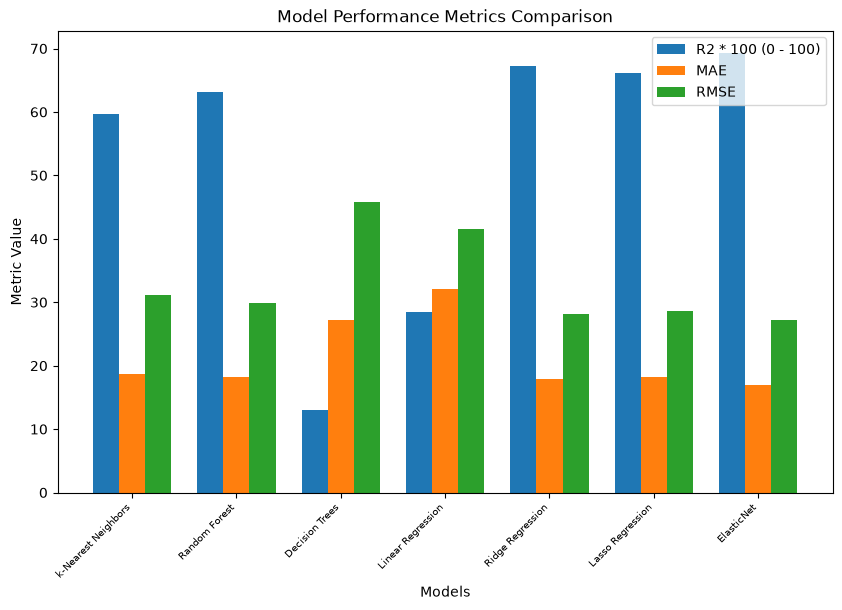

In [24]:
# Sample data
data = [
    knn_metrics,
    rf_metrics,
    metrics_dt,
    linear_metrics,
    metrics_ridge,
    metrics_lasso,
    metrics_enet
]

# New labels for the groups (models)
group_labels = ['k-Nearest Neighbors', 'Random Forest', 'Decision Trees', 'Linear Regression', 'Ridge Regression', 'Lasso Regression', 'ElasticNet']
# New labels for the elements (metrics)
element_labels = ['R2 * 100 (0 - 100)', 'MAE', 'RMSE']
# Set the width of the bars
bar_width = 0.25
# Set the positions of the bar groups on the x-axis
x_positions = np.arange(len(group_labels))
# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the bars for each of the three elements in all groups
for i in range(3):
    values = [array[i] for array in data]
    ax.bar(x_positions + i * bar_width, values, bar_width, label=element_labels[i])

# Set the title and labels
ax.set_title('Model Performance Metrics Comparison')
ax.set_xlabel('Models')
ax.set_ylabel('Metric Value')

# Set the x-axis tick positions and labels
ax.set_xticks(x_positions + bar_width)
ax.set_xticklabels(group_labels, rotation=45, ha='right', fontsize=7)
# Add a legend to distinguish the elements
ax.legend()

plt.show()

### Let's create a baseline to predict our model against

In [25]:
baseline = np.full(y_test.shape, y_test['incidence_per_1000'].mean())
mean_absolute_error(y_test, baseline)
# This baseline's accuracy is misleading. It's not that bad for a static prediction. It's because of the data's skewed structure

30.740060907810335

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21],
 [Text(0, 0, 'spray_status'),
  Text(1, 0, 'dist_missing'),
  Text(2, 0, 'humidity'),
  Text(3, 0, 'temp'),
  Text(4, 0, 'max_temp'),
  Text(5, 0, 'min_temp'),
  Text(6, 0, 'prev2_rainfall'),
  Text(7, 0, 'prev3_rainfall'),
  Text(8, 0, 'prev4_rainfall'),
  Text(9, 0, 'prev2_humidity'),
  Text(10, 0, 'prev3_humidity'),
  Text(11, 0, 'prev4_humidity'),
  Text(12, 0, 'prev2_temp'),
  Text(13, 0, 'prev3_temp'),
  Text(14, 0, 'prev4_temp'),
  Text(15, 0, 'prev2_max_temp'),
  Text(16, 0, 'prev3_max_temp'),
  Text(17, 0, 'prev4_max_temp'),
  Text(18, 0, 'prev2_min_temp'),
  Text(19, 0, 'prev3_min_temp'),
  Text(20, 0, 'prev4_min_temp'),
  Text(21, 0, 'prev_incidence_per_1000')])

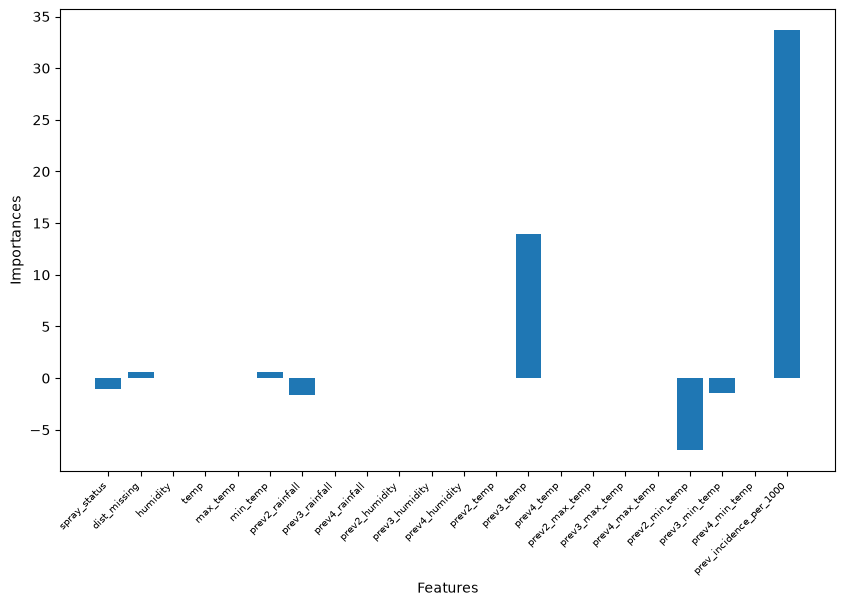

In [26]:
coef_df = pd.DataFrame({
    'features': X_train.columns,
    'coefs': lasso.best_estimator_.coef_
})
coef_df.sort_values('coefs')
plt.figure(figsize=(10, 6))
plt.xlabel('Features'); plt.ylabel('Importances')
plt.bar(coef_df['features'], coef_df['coefs'])
plt.xticks(rotation=45, ha='right', fontsize=7)

##### This feels like cheating because the model is performing so well when prev_month_incidence is given as a feature
##### It's >3x more important than the best of the rest
##### But this is forecasting after all. So I guess it's fine

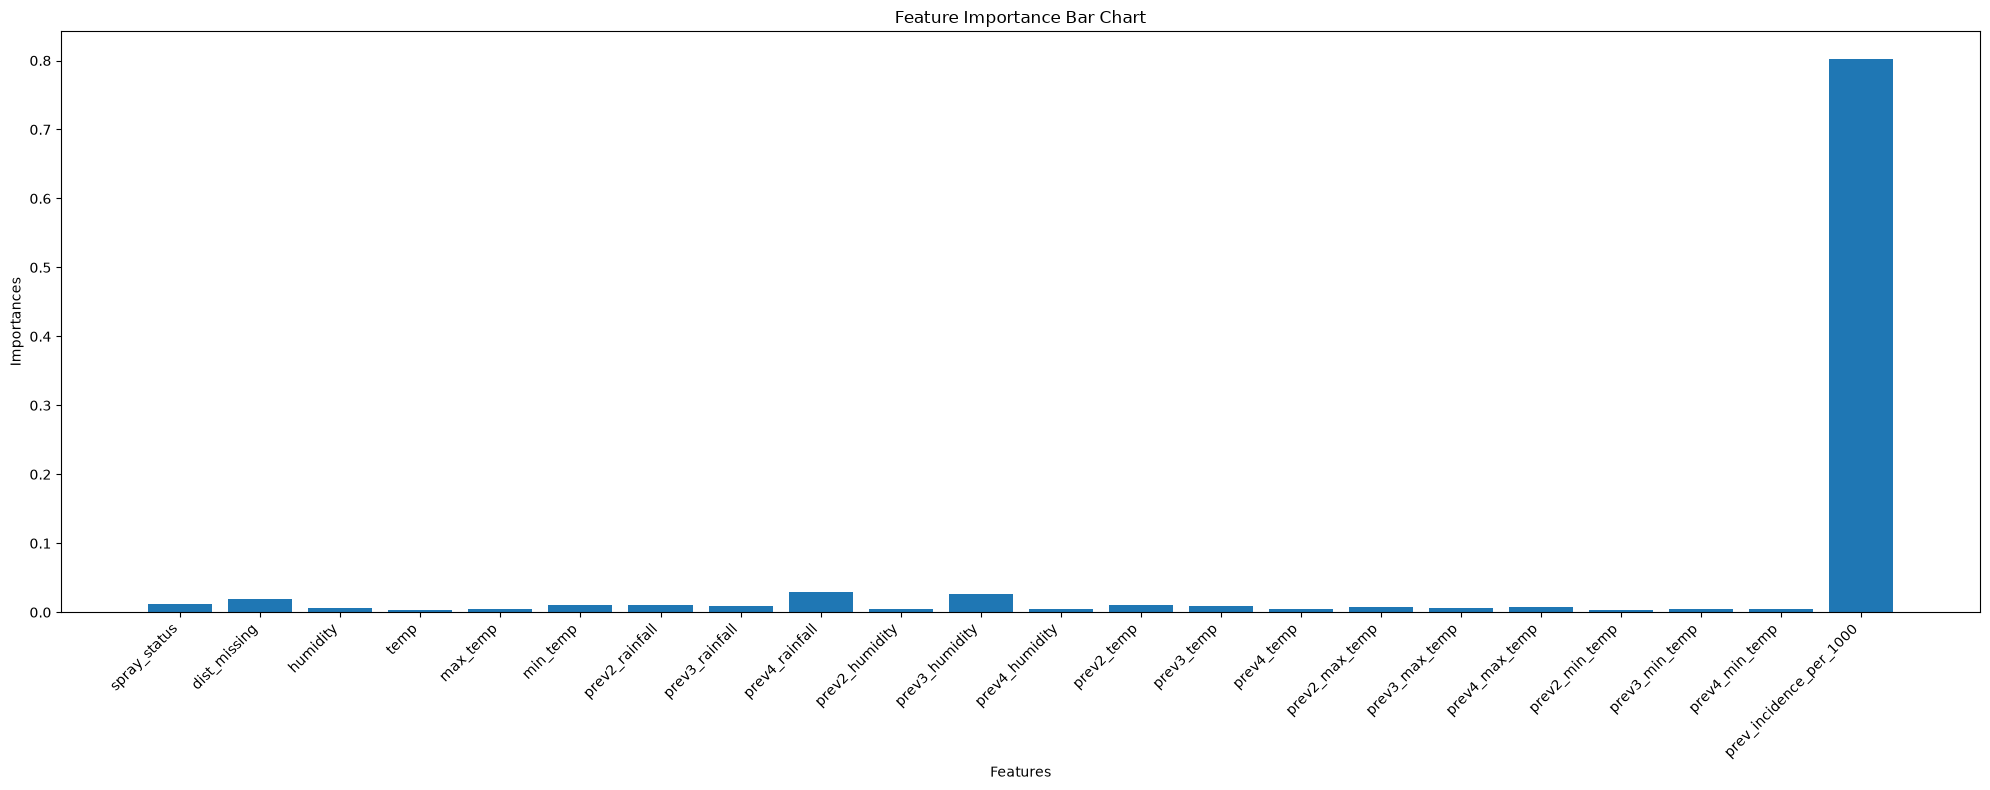

In [27]:
# Let's plot the feature importance and HOPE it's not overfitting
importances = model.feature_importances_
plt.figure(figsize=(20, 8))
plt.bar(X_test.columns, importances)
plt.xlabel('Features'); plt.ylabel('Importances')
plt.title('Feature Importance Bar Chart')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

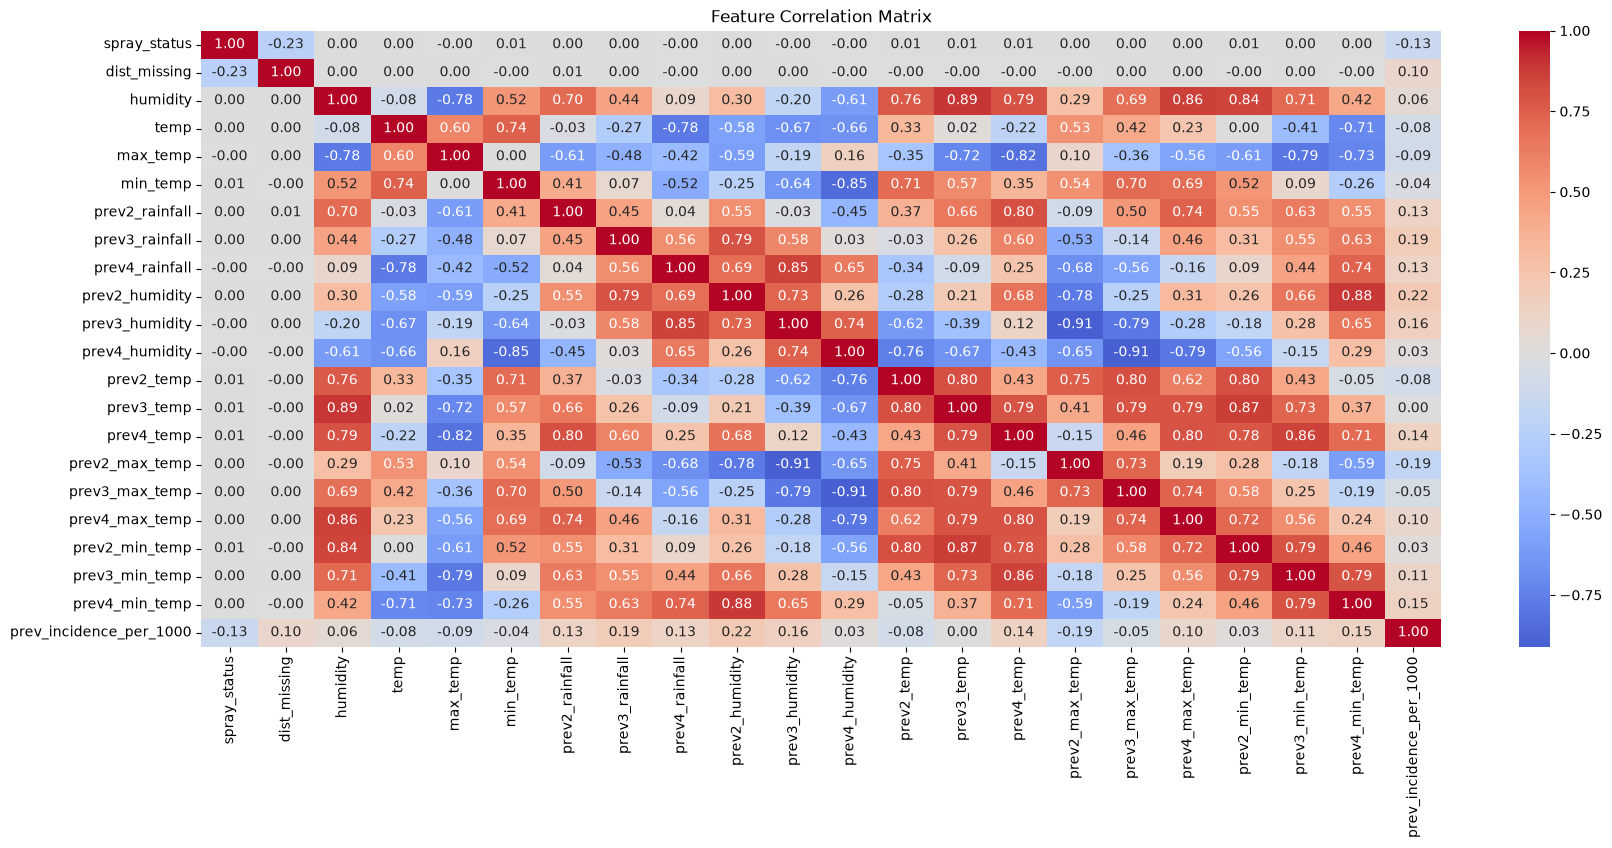

In [28]:
corr_matrix = X_train.corr()

plt.figure(figsize=(20,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', center=0)
plt.title("Feature Correlation Matrix")
plt.show()
# It's seems that rainfall and rainfall_total have a substantial similarity that dropping one won't hurt the model.
# Maybe something interesting to write on the paper

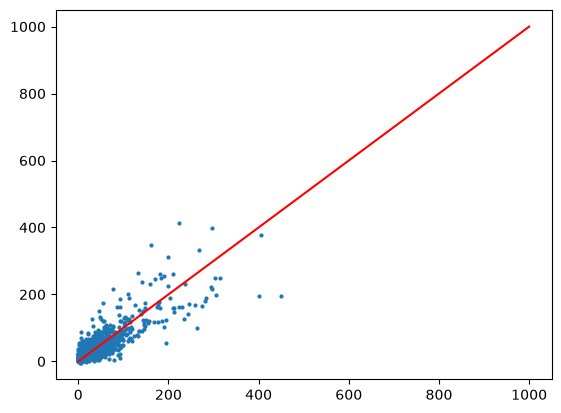

In [29]:
plt.scatter(y_test, lasso.predict(X_test_scaled), s=4)
plt.plot([0, 1000], [0, 1000], c='r')
plt.show()

#### The target variable has 60% unique values, that means the can't model has less chance of overfitting. 👍

In [30]:
len(df['prev_incidence_per_1000']), len(df['prev_incidence_per_1000'].unique())

(3676, 2299)

##### I should come to a conclusion in the paper that models predict better when given other quantifiable parameters that weren't listed here.
##### Climate data and spatial data alone isn't enough to reasonably predict malaria incidence in villages
##### People should focus on recording other possible parameters for better predictions
##### Because prev_incidence_per_1000 alone increased the R2 substantially, meaning it carries information other features don't

# <center>--------------------------------------------------------------------------------------------</center>

# Brainspace

##### The fact that village_code, total_rdts, and dist_missing make better predictors than climate data suggests something important

This is because they all have one thing in common: spatial specificity <br>
That should be why our model was predicting very poorly (sometimes even worse than our baseline), even with the best train / test split,
after removing parameters related to specific villages.
This suggests that it would be logical to add, in training and predictions, a parameter for showing how prone a village is to malaria incidences.<br>
<b>Note: We shouldn't just include village "codes" or IDs for each village. That would cause overfitting. It would just learn a village's historical average.</b><br>
Therefore, engineering a quantitative index (not a qualitative / one-hot encoded one, such as village codes) that would tell the model how prone the place is to malaria can boost model accuracy and interpretability.<br>
The next step is figuring out how to create such indexes. Maybe from previous incidences or other undocumented parameters.

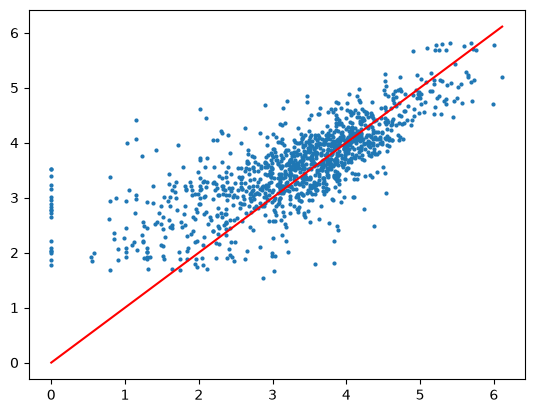

In [31]:
plt.scatter(np.log1p(y_test), np.log1p(model.predict(X_test_scaled)), s=4); plt.plot([0, np.max(np.log1p(y_test))], [0, np.max(np.log1p(y_test))], c='r')

In [32]:
joblib.dump(knn, '../Model Pkl Files/knn.pkl')
joblib.dump(model, '../Model Pkl Files/rf.pkl')
joblib.dump(dt, '../Model Pkl Files/dt.pkl')
joblib.dump(linear, '../Model Pkl Files/linear.pkl')
joblib.dump(ridge, '../Model Pkl Files/ridge.pkl')
joblib.dump(lasso, '../Model Pkl Files/lasso.pkl')
joblib.dump(elasticnet, '../Model Pkl Files/elasticnet.pkl')

['../Model Pkl Files/elasticnet.pkl']

In [33]:
df.isna().any().sum()

np.int64(0)